In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib as plt
import networkx as nx
import mip

BUILDING_NAME = "Edificio1.csv"

ASCENDING_SPEED = 1.0
DESCENDING_SPEED = 2.0
HORIZONTAL_SPEED = 1.5

ASCENDING_ENERGY = 50
DESCENDING_ENERGY = 5
HORIZONTAL_ENERGY = 10

X_BASE_RANGE = range(-8, 6) if "Edificio1.csv" == BUILDING_NAME else range(-10, 11)
Y_BASE_RANGE = range(-17, -14) if "Edificio1.csv" == BUILDING_NAME else range(-31, -29)
Z_BASE = 0

BATTERY_CAPACITY = 3600 if "Edificio1.csv" == BUILDING_NAME else 21600  # 1 Wh is 3600 J

Y_ENTRY_POINT = -12.5 if "Edificio1.csv" == BUILDING_NAME else -20.0

# Reading CSV and creating pairs


In [2]:
# loading building csv data

nodes = pd.read_csv(BUILDING_NAME)

# Creating Bases and entry points

In [3]:
# Adding is_base and is_entry_point columns

nodes["is_base"] = False

nodes["is_entry_point"] = nodes["y"] <= Y_ENTRY_POINT


# Creating new rows for base points
bases = []
for x in X_BASE_RANGE:
    for y in Y_BASE_RANGE:
        bases.append(
            {"x": x, "y": y, "z": Z_BASE, "is_base": True, "is_entry_point": False}
        )

# Appending base rows to the building dataframe
building = pd.concat([nodes, pd.DataFrame(bases)], ignore_index=True)

building.to_csv("building.csv", index=False)

# Merging nodes to create pairs

In [4]:
# setting node numbering from 1 to n
building.index += 1

# generating all possible pairs of points (edges)
nodes_pairs = (
    building.rename_axis("source_node")
    .reset_index()
    .merge(building.rename_axis("target_node").reset_index(), how="cross")
)

# removing self-self pairs
nodes_pairs = nodes_pairs[
    nodes_pairs["source_node"] != nodes_pairs["target_node"]
]  # keeping only pairs with different points

In [5]:
first_point_cols = ["x_x", "y_x", "z_x"]
second_point_cols = ["x_y", "y_y", "z_y"]
diff_cols = ["dx", "dy", "dz"]

# Computing distances 

In [6]:
# function to determine if two points are connected based on distance and coordinate deltas


def process_connections(dataframe):
    # distances and deltas on coordinates
    dataframe[diff_cols] = (
        dataframe[second_point_cols].values - dataframe[first_point_cols].values
    )
    dataframe["euclidean_distance"] = np.sqrt(
        (dataframe[diff_cols] ** 2).sum(axis=1)
    )  # axis=1 sum on columns

    # conditions near and tunnel
    condition_near = dataframe["euclidean_distance"] <= 4.0

    condition_tunnel = (
        ((dataframe["dx"].abs() <= 0.5) & (dataframe["dy"].abs() <= 0.5))
        | ((dataframe["dy"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
        | ((dataframe["dx"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
    )

    condition_tunnel_and_not_far = (
        dataframe["euclidean_distance"] <= 11.0
    ) & condition_tunnel

    # if the arc is from base to entry point or viceversa
    condition_base_to_entry_point = (
        (dataframe["is_base_x"]) & (dataframe["is_entry_point_y"])
    ) | ((dataframe["is_base_y"]) & (dataframe["is_entry_point_x"]))

    # l'unica connessione ammessa è base <-> entry point
    condition_involves_base = dataframe["is_base_x"] | dataframe["is_base_y"]

    # Gli archi tra nodi griglia usano le regole di distanza (near/tunnel)
    # Gli archi con basi usano SOLO la regola base <-> entry point
    dataframe["are_connected"] = (
        (condition_near & ~condition_involves_base)
        | (condition_tunnel_and_not_far & ~condition_involves_base)
        | condition_base_to_entry_point
    )
    return dataframe

In [7]:
nodes_pairs = process_connections(nodes_pairs)

nodes_pairs.to_csv("pairs.csv", index=False)

nodes_pairs.head()

,source_node,x_x,y_x,z_x,is_base_x,is_entry_point_x,target_node,x_y,y_y,z_y,is_base_y,is_entry_point_y,dx,dy,dz,euclidean_distance,are_connected
1,1,2.5,3.25,0.0,False,False,2,-6.0,3.25,0.0,False,False,-8.5,0.0,0.0,8.500000,True
2,1,2.5,3.25,0.0,False,False,3,-6.0,11.75,0.0,False,False,-8.5,8.5,0.0,12.020815,False
3,1,2.5,3.25,0.0,False,False,4,2.5,11.75,0.0,False,False,0.0,8.5,0.0,8.500000,True
4,1,2.5,3.25,0.0,False,False,5,2.5,3.25,11.0,False,False,0.0,0.0,11.0,11.000000,True
5,1,2.5,3.25,0.0,False,False,6,-6.0,3.25,11.0,False,False,-8.5,0.0,11.0,13.901439,False


In [8]:
# computing vertical distances on z and distances on horizontal plane x,y
nodes_pairs["d_horizontal"] = np.sqrt(nodes_pairs["dx"] ** 2 + nodes_pairs["dy"] ** 2)
nodes_pairs["d_vertical"] = nodes_pairs["dz"]

# dropping columns that are not useful anymore
nodes_pairs.drop(columns=["dx", "dy", "dz"], inplace=True)
nodes_pairs.drop(columns=["x_x", "y_x", "z_x", "x_y", "y_y", "z_y"], inplace=True)

# keeping only connected pairs
nodes_pairs = nodes_pairs[nodes_pairs["are_connected"] == True]
nodes_pairs.drop(columns=["are_connected"], inplace=True)

nodes_pairs.head(5)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,euclidean_distance,d_horizontal,d_vertical
1,1,False,False,2,False,False,8.500000,8.500000,0.0
3,1,False,False,4,False,False,8.500000,8.500000,0.0
4,1,False,False,5,False,False,11.000000,0.000000,11.0
18,1,False,False,19,False,False,4.007805,4.007805,0.0
19,1,False,False,20,False,False,1.030776,1.030776,0.0


# Function for time travel

In [9]:
# finding rows corresponding to different movement types

d_horizontal = nodes_pairs["d_horizontal"]
d_vertical = nodes_pairs["d_vertical"]
rows_horizontal = d_vertical == 0
rows_ascending = (d_horizontal == 0) & (d_vertical > 0)
rows_descending = (d_horizontal == 0) & (d_vertical < 0)
rows_oblique_ascending = (d_horizontal != 0) & (d_vertical > 0)
rows_oblique_descending = (d_horizontal != 0) & (d_vertical < 0)

In [10]:
# function for time travel based on movement types and speeds


def compute_time_travel(dataframe):
    dataframe.loc[rows_horizontal, "time_travel"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] / HORIZONTAL_SPEED
    )

    dataframe.loc[rows_ascending, "time_travel"] = (
        dataframe.loc[rows_ascending, "d_vertical"] / ASCENDING_SPEED
    )
    dataframe.loc[rows_descending, "time_travel"] = (
        -dataframe.loc[rows_descending, "d_vertical"] / DESCENDING_SPEED
    )

    dataframe.loc[rows_oblique_ascending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] / HORIZONTAL_SPEED,
        dataframe.loc[rows_oblique_ascending, "d_vertical"] / ASCENDING_SPEED,
    )

    dataframe.loc[rows_oblique_descending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_descending, "d_horizontal"] / HORIZONTAL_SPEED,
        -dataframe.loc[rows_oblique_descending, "d_vertical"] / DESCENDING_SPEED,
    )
    return dataframe

# Function for energy consumption


In [11]:
# function for energy cost based on movement types and energy consumption rates


def compute_energy_cost(dataframe):
    dataframe.loc[rows_horizontal, "energy_consumption"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] * HORIZONTAL_ENERGY
    )

    dataframe.loc[rows_ascending, "energy_consumption"] = (
        dataframe.loc[rows_ascending, "d_vertical"] * ASCENDING_ENERGY
    )
    dataframe.loc[rows_descending, "energy_consumption"] = (
        -dataframe.loc[rows_descending, "d_vertical"] * DESCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_ascending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] * HORIZONTAL_ENERGY
        + dataframe.loc[rows_oblique_ascending, "d_vertical"] * ASCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_descending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_descending, "d_horizontal"] * HORIZONTAL_ENERGY
        + -dataframe.loc[rows_oblique_descending, "d_vertical"] * DESCENDING_ENERGY
    )
    return dataframe

# Actually computing energy and time costs for arcs

In [12]:
# computing time travel and energy cost for each pair (edges)

nodes_pairs = compute_time_travel(nodes_pairs)

nodes_pairs = compute_energy_cost(nodes_pairs)

nodes_pairs.drop(
    columns=["d_horizontal", "d_vertical", "euclidean_distance"], inplace=True
)

nodes_pairs.head(10)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,time_travel,energy_consumption
1,1,False,False,2,False,False,5.666667,85.000000
3,1,False,False,4,False,False,5.666667,85.000000
4,1,False,False,5,False,False,11.000000,550.000000
18,1,False,False,19,False,False,2.671870,40.078049
19,1,False,False,20,False,False,0.687184,10.307764
106,2,False,False,1,False,False,5.666667,85.000000
108,2,False,False,3,False,False,5.666667,85.000000
111,2,False,False,6,False,False,11.000000,550.000000
124,2,False,False,19,False,False,3.004626,45.069391
125,2,False,False,20,False,False,5.002777,75.041655


# Creating Graph with Networkx


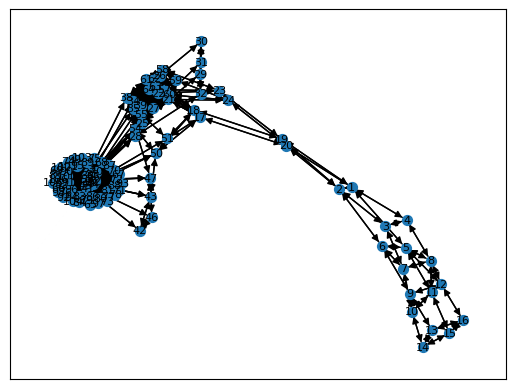

In [13]:
# creating directed graph G from the dataframe of edges with costs

G = nx.from_pandas_edgelist(
    nodes_pairs,  # dataframe containing edges
    source="source_node",  # indicating the start of the edge
    target="target_node",  # indicating the end of the edge
    edge_attr=["time_travel", "energy_consumption"],  # edge costs
    create_using=nx.DiGraph(),  # creating an oriented graph
)

nx.draw_networkx(G, node_size=50, font_size=8)

# MODELLO MIP

In [14]:
# IL DATAFRAME BASES CONTIENE TUTTE LE BASI
# IL DATAFRAME NODES CONTIENE I NODI DEL SET S
# IL NODES_PAIRS CONTIENE GLI ARCHI TRA TUTTI I NODI
# IL SET H È UN INSIEME DI NUMERI DA 0 A UN NUMERO k CHE VA STIMATO BENE

m = mip.Model("DroneTourPlanning")

# SETS AND PARAMETERS
# ---------------------------------------------------------------
N = building.index.tolist()  # All nodes
S = building[building["is_base"] == False].index.tolist()  # Service nodes
B = building[building["is_base"] == True].index.tolist()  # Bases nodes
print(f"set N = {N}")
print(f"set B = {B}")
print(f"set S = {S}")

A = G.edges  # set of arcs
print(f"set A = {A}")

t = {
    (u, v): data["time_travel"] for u, v, data in G.edges(data=True)
}  # dictionary of time travel costs
e = {
    (u, v): data["energy_consumption"] for u, v, data in G.edges(data=True)
}  # dictionary of energy consumption costs
print(f"time travel costs t = {t}")
print(f"energy consumption costs e = {e}")

C = BATTERY_CAPACITY  # battery capacity

set N = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106]
set B = [65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106]
set S = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64]
set A = [(1, 2), (1, 4), (1, 5), (1, 19), (1, 20), (2, 1), (2, 3), (2, 6), (2, 19), (2, 20), (4, 1), (4, 3), (4, 8), (5, 1), (5, 

# H E BIG M

In [15]:
# Calculate |H| according to formula: ceil(sum(e_in_min + e_out_min)/C * 1.5)
import math

min_energy_in_out = {}
for i in S:
    incoming = [e[j, i] for j in N if (j, i) in A]
    outgoing = [e[i, j] for j in N if (i, j) in A]
    min_energy_in = min(incoming) if incoming else float("inf")
    min_energy_out = min(outgoing) if outgoing else float("inf")
    min_energy_in_out[i] = min_energy_in + min_energy_out

sum_min_energies = sum(min_energy_in_out.values())
H_length = math.ceil((sum_min_energies / BATTERY_CAPACITY))
H = list(range(1, max(2, H_length + 1)))  # At least 1 tour
#worst case is H = 2 in building 2 
#H = [1,2]

print(f"set H = {H}")

set H = [1]


# VARIABILI

In [16]:
# VARIABLES
# ---------------------------------------------------------------
x = {
    (i, j, h): m.add_var(var_type=mip.BINARY, name=f"x_{i}_{j}_{h}")
    for i, j in A
    for h in H
}  # binary variable indicating if arc (i,j) is used in tour h

b = {
    i: m.add_var(var_type=mip.BINARY, name=f"b_{i}") for i in B
}  # binary variable indicating if base i is used

# SCF (Single Commodity Flow) variables for subtour elimination
# f[i,j,h] = flow on arc (i,j) in tour h
f = {
    (i, j, h): m.add_var(lb=0, ub=len(S), name=f"f_{i}_{j}_{h}")
    for i, j in A
    for h in H
}

# OBJ FUNCTION


In [17]:
m.objective = mip.minimize(mip.xsum(t[i, j] * x[i, j, h] for i, j in A for h in H))

# CONSTRAINTS

In [18]:
# (1) Only one base is selected
m += mip.xsum(b[i] for i in B) == 1

# (2) Each service node is visited at least once
for i in S:
    m += mip.xsum(x[j, i, h] for j in N for h in H if (j, i) in A) >= 1

# (3) Flow conservation for x (arc variables)
for i in N:
    for h in H:
        m += mip.xsum(x[j, i, h] for j in N if (j, i) in A) == mip.xsum(
            x[i, j, h] for j in N if (i, j) in A
        )

# (4) Trip departs from base only if selected
for base in B:
    for h in H:
        m += mip.xsum(x[base, j, h] for j in N if (base, j) in A) <= b[base]

# (5) Energy constraint
for h in H:
    m += mip.xsum(e[i, j] * x[i, j, h] for (i, j) in A) <= C

# (6) SCF Subtour Elimination
# Idea: il flusso parte dalla base e viene consumato ad ogni nodo visitato.
# Se c'è un sottotour senza base, non ha sorgente di flusso → infeasible.

# (6a) f_ij <= |S| * x_ij (flow only on active arcs)
for i, j in A:
    for h in H:
        m += f[i, j, h] <= len(S) * x[i, j, h]

# (6b) Flow conservation at service nodes: inflow - outflow = 1 if visited
for i in S:
    for h in H:
        inflow = mip.xsum(f[j, i, h] for j in N if (j, i) in A)
        outflow = mip.xsum(f[i, j, h] for j in N if (i, j) in A)
        visits = mip.xsum(x[j, i, h] for j in N if (j, i) in A)
        m += inflow - outflow == visits

# (6c) Flow at bases: la base è sorgente, il flusso netto uscente >= 0
# Non serve vincolo esplicito: i vincoli (6b) impongono già che il flusso
# totale consumato = nodi visitati. La base è l'unica sorgente possibile.

# (7) Symmetry Breaking
for h in range(len(H) - 1):
    m += mip.xsum(x[i, j, H[h]] for (i, j) in A) >= mip.xsum(
        x[i, j, H[h + 1]] for (i, j) in A
    )

In [19]:
print(f"Variabili: {m.num_cols}, Vincoli: {m.num_rows}")
m.optimize(max_seconds=3600)  # 40 minuti di test
print(f"\nStatus: {m.status}")


Variabili: 2982, Vincoli: 1748
Welcome to the CBC MILP Solver 
Version: Trunk
Build Date: Oct 24 2021 

Starting solution of the Linear programming relaxation problem using Dual Simplex

Clp0024I Matrix will be packed to eliminate 4 small elements
Coin0506I Presolve 1747 (-1) rows, 2981 (-1) columns and 11796 (-2) elements
Clp0014I Perturbing problem by 0.001% of 7.0528155 - largest nonzero change 0.00099836578 ( 0.47368303%) - largest zero change 0.00045832254
Clp0000I Optimal - objective value 122.72069
Coin0511I After Postsolve, objective 122.72069, infeasibilities - dual 0 (0), primal 0 (0)
Clp0032I Optimal objective 122.7206887 - 1295 iterations time 0.042, Presolve 0.00

Starting MIP optimization
Cgl0004I processed model has 1747 rows, 2981 columns (1511 integer (1511 of which binary)) and 11796 elements
Coin3009W Conflict graph built in 0.001 seconds, density: 0.034%
Cgl0015I Clique Strengthening extended 0 cliques, 0 were dominated
Cbc0045I Nauty: 10135 orbits (380 useful cover

In [20]:
if m.objective_value:
    print(f"Obiettivo: {m.objective_value:.2f}")
if m.objective_bound:
    print(f"Lower bound: {m.objective_bound:.2f}")
gap = abs(m.objective_value - m.objective_bound) / abs(m.objective_value)
print(f"GAP: {gap:.4f}")
print(m.status)

Obiettivo: 160.88
Lower bound: 154.91
GAP: 0.0371
OptimizationStatus.FEASIBLE


In [21]:
# Salvataggio del modello in formato leggibile
m.write('model.lp')

# Salvataggio della soluzione
if m.num_solutions:
    with open('solution.txt', 'w') as file:
        file.write(f"Objective: {m.objective_value}\n")
        for var in m.vars:
            file.write(f"{var.name} = {var.x}\n")

In [22]:

if m.num_solutions:

    #trovo la base che è stata attivata 
    for i in B:
        if b[i].x ==1.0:
            active_base = i
            break
    #definisco per salvare i vari percorsi (path1, path2...)
    all_paths = []
    
    #in base al path in cui sono identifico gli archi che sono stati usati
    for idx, h in enumerate(H):
        #dizionario per salvare il nodo prossimo j dato il nodo i 
        next_node = {}
        for (i, j) in A:
            if x[i, j, h].x == 1.0:
                #se è il primo arco creo una lista 
                if i not in next_node:
                    next_node[i] = []
                #inserisco il nodo di arrivo j dato il nodo di partenza i 
                #li metto in una lista perché dato un nodo i questo può avere più trasnizione di output
                next_node[i].append(j)

        #next_node[i] è la lista di tutti i nodi raggiungibili da i 
        
        
        #lo stack sono i nodi da esplorare, parto dalla base
        stack = [active_base]
        path = []
        
        #finche c'è qualcosa nello stack vado avanti
        while stack:
            v = stack[-1] #prendo ultimo elemento
            if v in next_node and next_node[v]: #se v ha ancora archi non usati
               
                u = next_node[v].pop() #prendo un nodo target (un arco) e lo rimuovo dalla lista
                stack.append(u)#metto la destinazione nello stack 
            else:
                #se non ha archi uscenti li ho già esplorati e la inserisco nello stack
                path.append(stack.pop())
        
        # il percorso è al contrario
        path = path[::-1]
        
        
        path_str = ["0"]  #base
        for node in path[1:]:
            if node == active_base:
                path_str.append("-0")
            else:
                path_str.append("-" + str(node))
        
        print(f"Viaggio {h}: {''.join(path_str)}")
        all_paths.append(path)

Viaggio 1: 0-49-44-41-45-48-53-33-37-25-29-32-31-30-26-38-61-62-57-22-34-54-47-46-42-43-50-18-17-51-55-35-21-60-59-24-20-1-4-8-11-15-14-13-16-12-5-6-9-10-7-3-2-19-23-58-63-64-39-27-28-40-36-56-52-0


In [23]:
#test per verificare se tutti i 64 nodi sono acceduti almeno una volta
valori = [
    33, 37, 25, 28, 27, 39, 35, 55, 51, 17, 18, 19,
    2, 6, 9, 6, 5, 12, 8, 11, 15, 16, 13, 14,
    10, 7, 3, 4, 1, 20, 24, 23, 19, 18,
    50, 43, 42, 43, 49, 44, 41, 0,
    0, 52, 56, 40, 36, 28, 32, 29, 30, 31, 27, 39,
    64, 63, 59, 58, 59, 21, 60, 57, 22, 26,
    61, 62, 61, 38, 34, 54, 47, 46, 47, 53, 48, 45, 0
]
i=0
for i in range(65):
    if i in valori:
        continue
    else:
        print(f"{i} non è in valori")

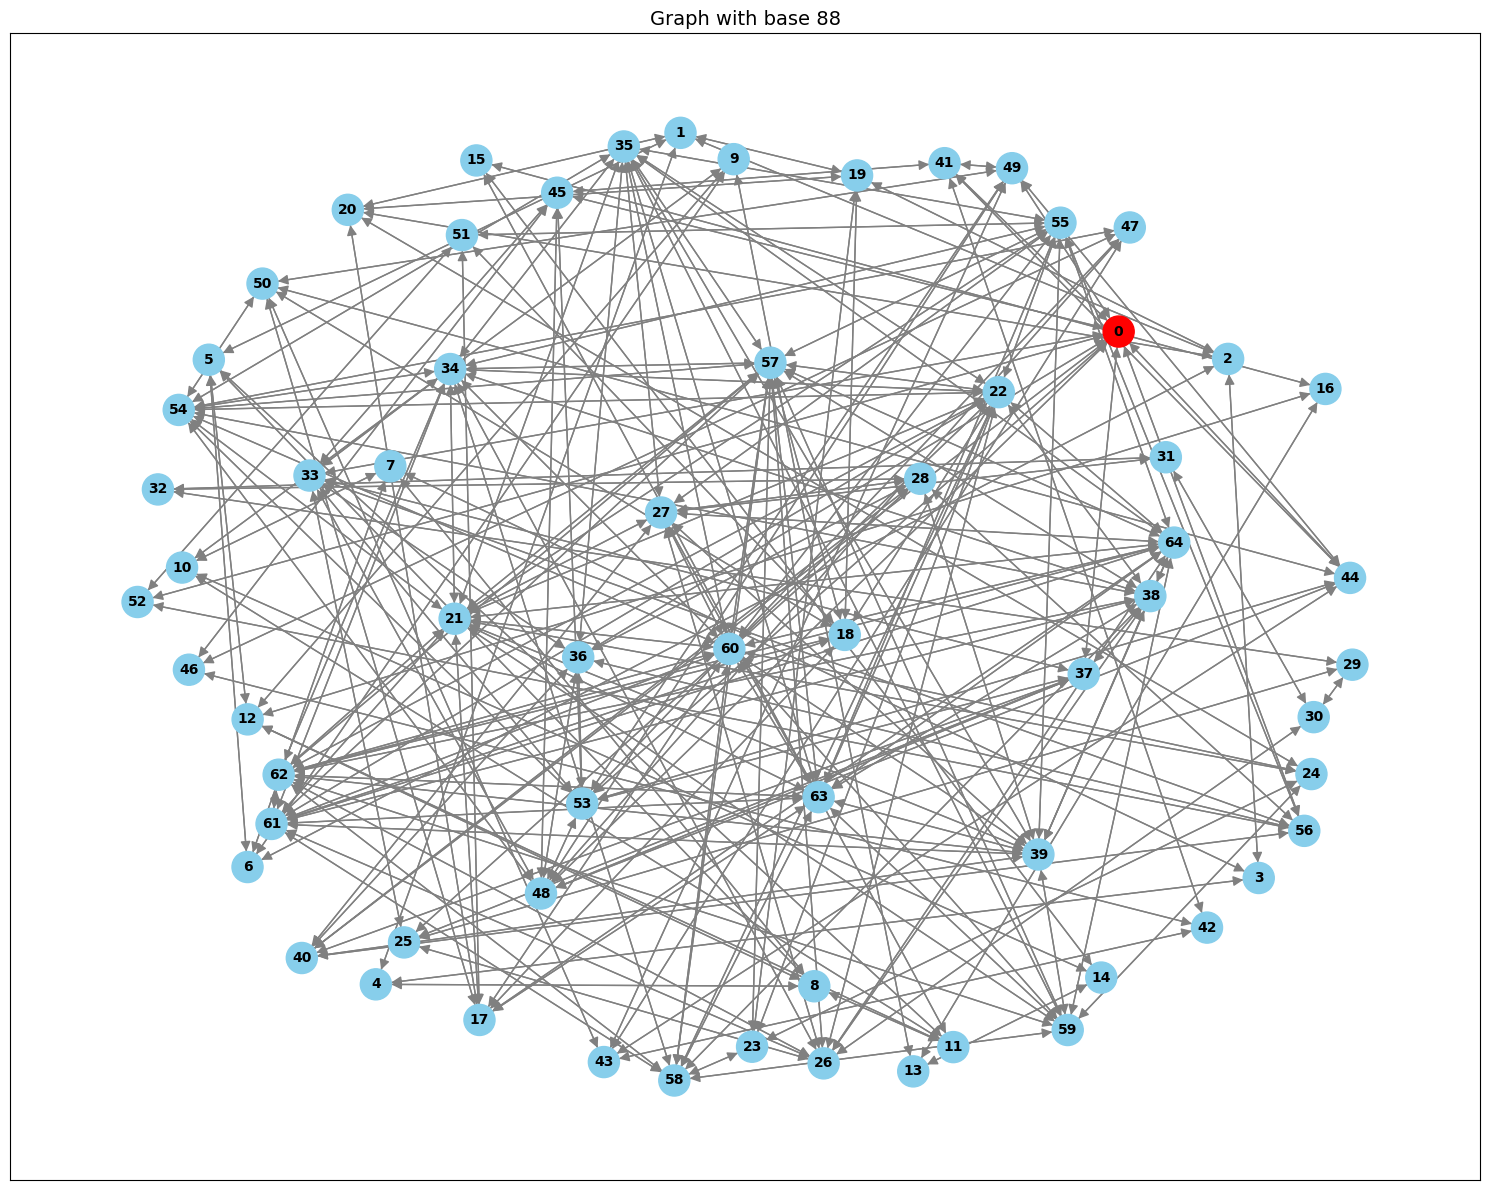

In [24]:
import matplotlib.pyplot as plt

#creo una lista delle basi da rimuovere 

remove_bases = [b for b in B if b != active_base]
#print(basi_da_rimuovere)

#creo il grafo senza le basi
G_sub = G.copy()
G_sub.remove_nodes_from(remove_bases)

plt.figure(figsize=(15, 12))

# k controlla la distanza tra i nodi 
pos = nx.spring_layout(G_sub, k=2, iterations=50, seed=42)

#colore rosso per la base 
node_colors = ['red' if n == active_base else 'skyblue' for n in G_sub.nodes()]

#0 se è la base altrimenti i valore del nodo
labels = {n: (0 if n == active_base else n) for n in G_sub.nodes()}

nx.draw_networkx(
    G_sub, 
    pos=pos,
    labels=labels, 
    node_size=500,  
    node_color=node_colors, 
    font_size=10,           
    font_weight='bold',
    edge_color='gray',
    arrows=True,
    arrowsize=15
)

plt.title(f"Graph with base {active_base}", fontsize=14)
#plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_176627/1060786694.py:52: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=12)


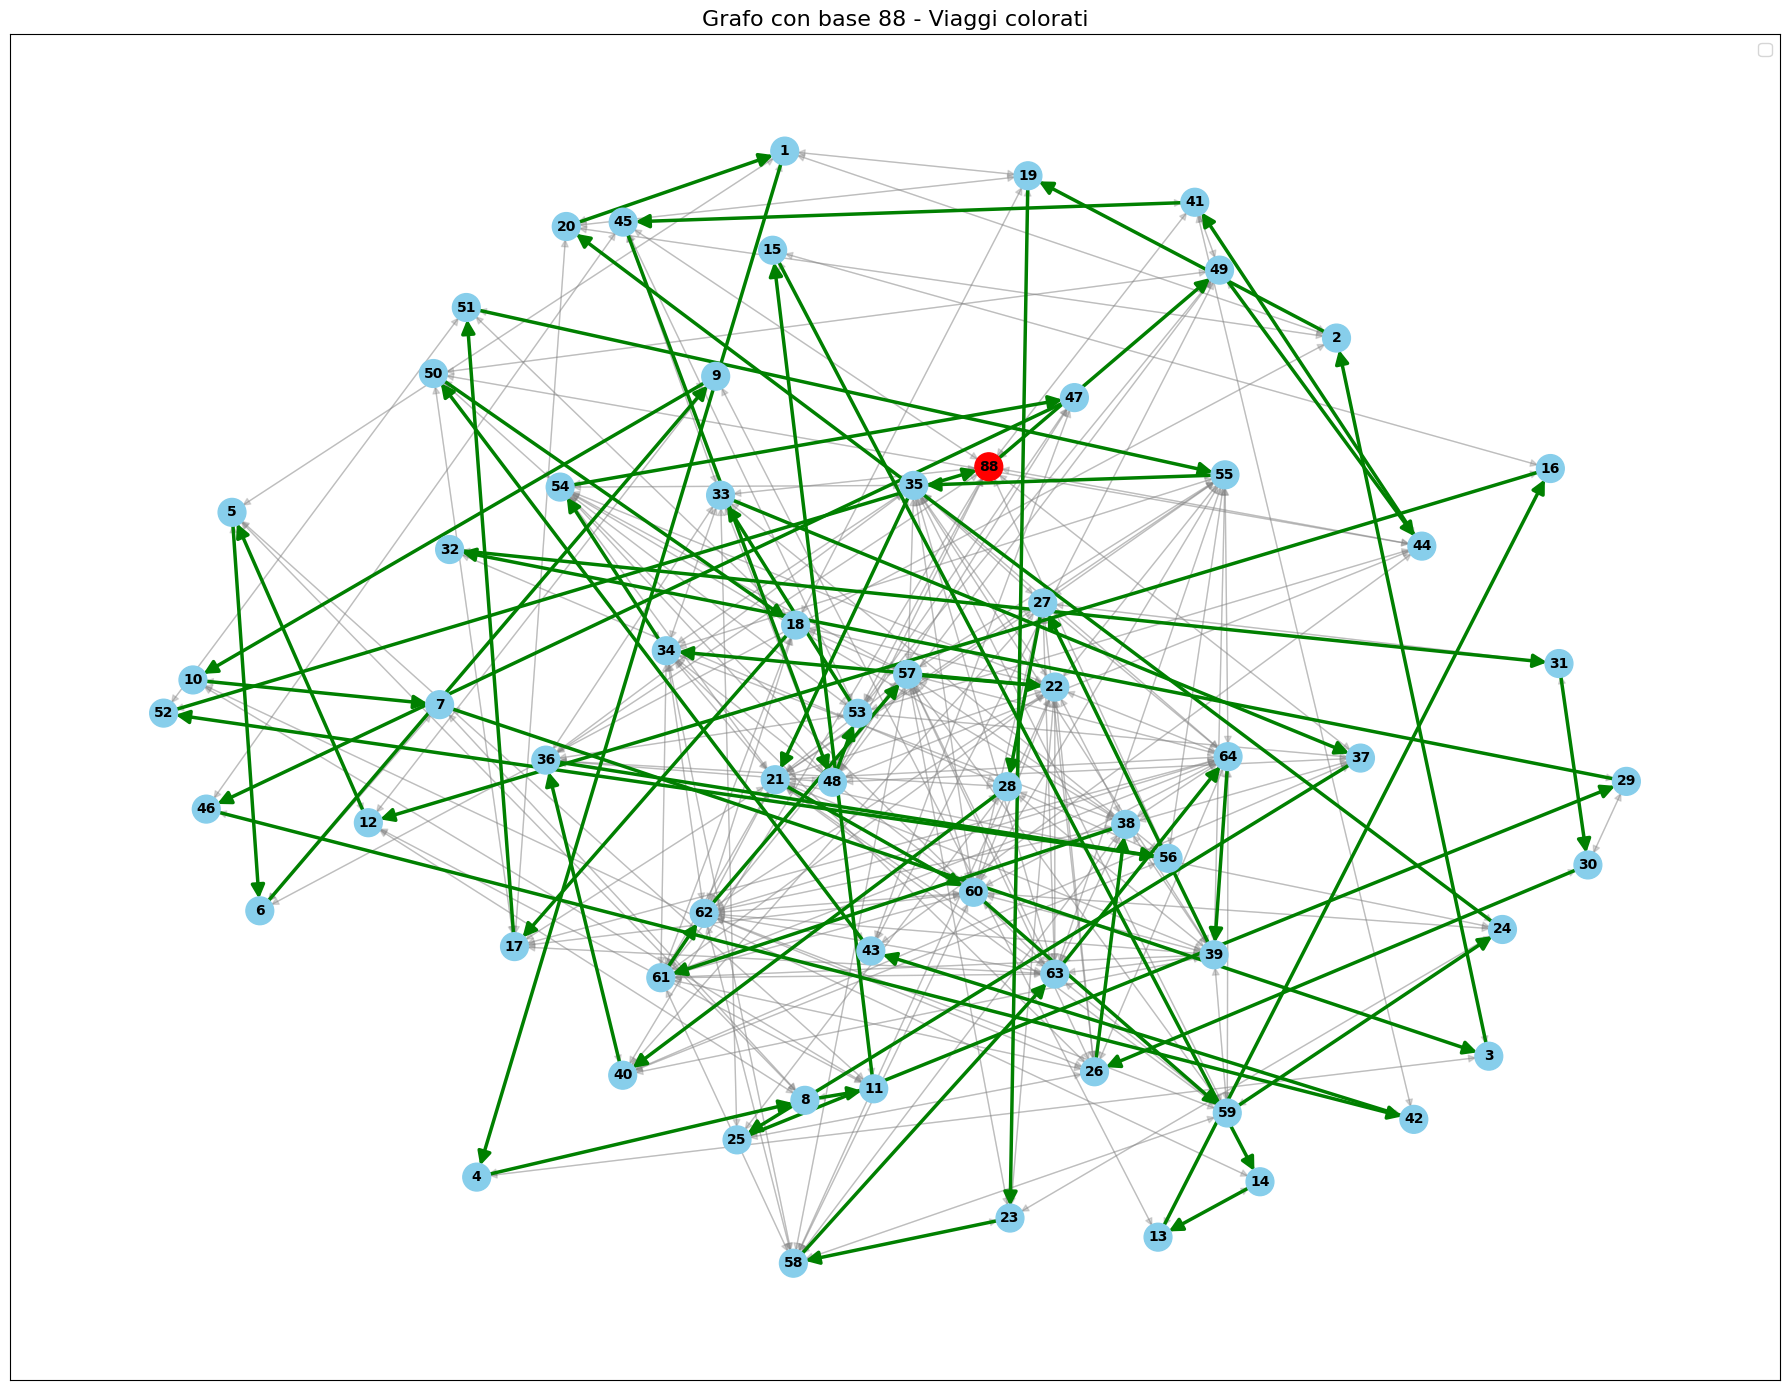

In [29]:
import matplotlib.pyplot as plt

#creo una lista delle basi da rimuovere 

remove_bases = [b for b in B if b != active_base]
#print(basi_da_rimuovere)

#creo il grafo senza le basi
G_sub = G.copy()
G_sub.remove_nodes_from(remove_bases)

plt.figure(figsize=(18, 14))

#k controlla la distanza tra i nodi
pos = nx.spring_layout(G_sub, k=2.5, iterations=100, seed=42)


node_colors = ['red' if n == active_base else 'skyblue' for n in G_sub.nodes()]

#0 se è la base altrimenti i valore del nodo
labels = {n: (0 if n == active_base else n) for n in G_sub.nodes()}

# Estrai gli archi dai path
path_edges = [[], []]  # lista di archi per ogni path
colors_path = ['green', 'orange']  # colori per i due path

for idx, path in enumerate(all_paths):
    
    # all_paths contiene già liste di interi 
    # creo coppie di archi 
    for i in range(len(path) - 1):
        path_edges[idx].append((path[i], path[i+1]))

#disegno i nodi
nx.draw_networkx_nodes(G_sub, pos, node_size=400, node_color=node_colors)
nx.draw_networkx_labels(G_sub, pos, font_size=10, font_weight='bold')

#collego tutti i nodi
all_path_edges = set(path_edges[0] + path_edges[1])
other_edges = [e for e in G_sub.edges() if e not in all_path_edges]
nx.draw_networkx_edges(G_sub, pos, edgelist=other_edges, edge_color='gray', 
                       arrows=True, arrowsize=12, alpha=0.3)

#archi dei path 
for idx, edges in enumerate(path_edges):
    
    nx.draw_networkx_edges(G_sub, pos,  edgelist=edges, edge_color=colors_path[idx], 
                               arrows=True, arrowsize=20, width=2.5, 
                               label=f'Viaggio {idx+1}')

plt.title(f"Grafo con base {active_base} - Viaggi colorati", fontsize=16)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()